### Model comparison, enhancement and deployment

This notebook compares four text classifiers against the majority-class baseline, evaluates a training-only hyperparameter optimisation strategy, and exports a model for a separate web application.

In [116]:
# load data
import json
import re
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, f1_score, classification_report
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.pipeline import FeatureUnion
from sklearn.model_selection import cross_validate
from sklearn.feature_selection import SelectKBest, chi2

In [117]:
# load file
path = Path("../data/processed/cleaned_research_abstracts.csv")

df = pd.read_csv(path)

In [118]:
# view file
print(df)

                                         DOI  \
0                       10.1155/2021/1071145   
1                 10.1007/s43546-022-00384-2   
2                           10.1002/for.2667   
3                 10.1007/s42973-021-00091-x   
4                  10.1007/s40258-012-0003-z   
...                                      ...   
1118                      10.1007/bf00123887   
1119  10.1093/acrefore/9780190625979.013.171   
1120                  10.1287/mnsc.2013.1812   
1121                        10.2118/22022-pa   
1122               10.1017/s1365100504030202   

                                               Abstract      Label  \
0     Forward-looking forecasting of the inflation r...         ai   
1     Our study examined the disaggregation of infla...         ai   
2     This paper develops a dynamic factor model tha...  classical   
3     In this paper, I use a simple SIR Macro model ...  classical   
4     BackgroundGame theory is useful for identifyin...  classical   
...

In [119]:
# view dataframe
df.head()

,DOI,Abstract,Label,Clean_Abstract
0,10.1155/2021/1071145,Forward-looking forecasting of the inflation r...,ai,forward-looking forecasting of the inflation r...
1,10.1007/s43546-022-00384-2,Our study examined the disaggregation of infla...,ai,our study examined the disaggregation of infla...
2,10.1002/for.2667,This paper develops a dynamic factor model tha...,classical,this paper develops a dynamic factor model tha...
3,10.1007/s42973-021-00091-x,"In this paper, I use a simple SIR Macro model ...",classical,in this paper i use a simple sir macro model t...
4,10.1007/s40258-012-0003-z,BackgroundGame theory is useful for identifyin...,classical,backgroundgame theory is useful for identifyin...


In [120]:
# inspect shape
print("Data shape:", df.shape)

Data shape: (1123, 4)


In [121]:
# validate prepared data
print("Dataset shape:", df.shape)
print("Duplicate abstracts:", df["Clean_Abstract"].duplicated().sum())
print("Missing abstracts:", df["Clean_Abstract"].isna().sum())

assert df["Clean_Abstract"].duplicated().sum() == 0, \
    "Duplicate cleaned abstracts remain. Rerun Notebook 01."

assert df["Clean_Abstract"].notna().all(), \
    "Missing cleaned abstracts detected."

X = df["Clean_Abstract"]
y = df["Label"]

print("\nClass distribution:")
print(y.value_counts())

print("\nInput feature:", X.name)
print("Target:", y.name)


Dataset shape: (1123, 4)
Duplicate abstracts: 0
Missing abstracts: 0

Class distribution:
Label
classical    888
ai           235
Name: count, dtype: int64

Input feature: Clean_Abstract
Target: Label


In [122]:
# split data
SEED=42

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

def text_pipeline(estimator):
    return Pipeline([
        ('tfidf', TfidfVectorizer(stop_words='english', ngram_range=(1, 2),
                                  min_df=2, max_df=0.95, sublinear_tf=True)),
        ('model', estimator)
    ])

print('Training:', len(X_train), 'Testing:', len(X_test))

Training: 898 Testing: 225


In [123]:
# evaluate results
def evaluate_model(name, model):
    train_pred = model.predict(X_train)
    test_pred = model.predict(X_test)
    return {'model': name,
            'train_accuracy': accuracy_score(y_train, train_pred),
            'test_accuracy': accuracy_score(y_test, test_pred),
            'train_macro_f1': f1_score(y_train, train_pred, average='macro', zero_division=0),
            'test_macro_f1': f1_score(y_test, test_pred, average='macro', zero_division=0)}


In [124]:
# baseline for comparison
baseline = text_pipeline(DummyClassifier(strategy='most_frequent'))
baseline.fit(X_train, y_train)
results = [evaluate_model('Majority baseline', baseline)]

### Model Comparison

I trained four machine learning models to classify research abstracts as either `ai` or `classical`:

- Multinomial Naive Bayes
- Logistic Regression
- Linear Support Vector Classifier (LinearSVC)
- Random Forest

All four models use TF-IDF features and the same stratified training and testing split to allow a consistent comparison.

I used accuracy and macro-F1 to evaluate the models on both the training and testing datasets. Macro-F1 is particularly important because the dataset contains more `classical` abstracts than `ai` abstracts.

The training and testing results are compared to assess how well each model generalises to unseen abstracts. The models are also compared against the majority-class baseline developed in Question 1.

In [125]:
# train models
candidates = {
    'MultinomialNB': MultinomialNB(),
    'LogisticRegression': LogisticRegression(max_iter=1500, class_weight='balanced', random_state=SEED),
    'LinearSVC': LinearSVC(class_weight='balanced', random_state=SEED),
    'RandomForest': RandomForestClassifier(n_estimators=150, class_weight='balanced',
                                           random_state=SEED, n_jobs=-1),
}
fitted = {}
for name, estimator in candidates.items():
    pipeline = text_pipeline(estimator)
    pipeline.fit(X_train, y_train)
    fitted[name] = pipeline
    results.append(evaluate_model(name, pipeline))
comparison = pd.DataFrame(results).sort_values('test_macro_f1', ascending=False)
print(comparison.round(3).to_string(index=False))

             model  train_accuracy  test_accuracy  train_macro_f1  test_macro_f1
         LinearSVC           0.999          0.920           0.998          0.873
LogisticRegression           0.988          0.907           0.982          0.860
      RandomForest           1.000          0.911           1.000          0.838
     MultinomialNB           0.846          0.809           0.666          0.525
 Majority baseline           0.791          0.791           0.442          0.442



### Model Comparison and Interpretation

I trained four machine learning models to classify research abstracts as either `ai` or `classical` and compared their performance against the majority-class baseline.

LinearSVC achieved the highest test accuracy of 92.0% and macro-F1 of 0.873, followed by Logistic Regression with 90.7% accuracy and 0.860 macro-F1. Random Forest achieved 91.1% accuracy and 0.838 macro-F1, while Multinomial Naive Bayes achieved 80.9% accuracy and 0.525 macro-F1.

All four models outperformed the majority-class baseline, which achieved 79.1% accuracy and 0.442 macro-F1. However, Multinomial Naive Bayes only showed a small improvement in accuracy, demonstrating why accuracy alone is insufficient when evaluating an imbalanced dataset.

LinearSVC achieved a training macro-F1 of 0.998 compared with 0.873 on the testing data. Similarly, Random Forest achieved a perfect training macro-F1 of 1.000 but only 0.838 on the testing data. These differences suggest possible overfitting, as both models performed considerably better on the training data than on unseen abstracts.

Logistic Regression achieved a training macro-F1 of 0.982 and a testing macro-F1 of 0.860, also showing some reduction in generalisation performance.

Although Random Forest achieved slightly higher test accuracy than Logistic Regression, Logistic Regression achieved a higher macro-F1. This suggests that Logistic Regression provides more balanced performance across the two classes.

Based on the results, LinearSVC is the strongest model because it achieved the highest testing accuracy and macro-F1.

Original CV macro-F1: 0.8508
Tuned CV macro-F1: 0.8508
Best parameters: {'model__C': 1, 'model__class_weight': 'balanced', 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}
CV improvement: 0.0

Model comparison:
             model  train_accuracy  test_accuracy  train_macro_f1  test_macro_f1
   Tuned LinearSVC           0.999          0.920           0.998          0.873
         LinearSVC           0.999          0.920           0.998          0.873
LogisticRegression           0.988          0.907           0.982          0.860
      RandomForest           1.000          0.911           1.000          0.838
     MultinomialNB           0.846          0.809           0.666          0.525
 Majority baseline           0.791          0.791           0.442          0.442

Tuned classification report:
              precision    recall  f1-score   support

          ai       0.85      0.74      0.80        47
   classical       0.93      0.97      0.95       178

    accuracy               

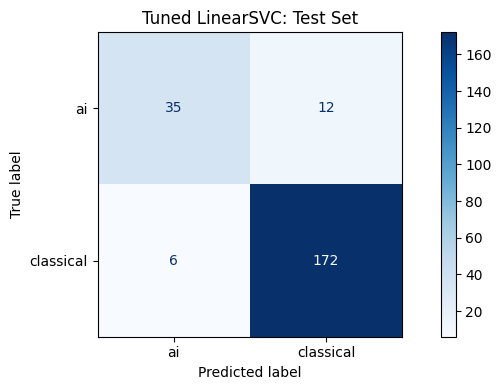


Cross-validation comparison:
LinearSVC             0.850828
Tuned LinearSVC       0.850828
LogisticRegression    0.840014
RandomForest          0.815859
MultinomialNB         0.494335
dtype: float64

Selected model: LinearSVC

Final classification report:
              precision    recall  f1-score   support

          ai       0.85      0.74      0.80        47
   classical       0.93      0.97      0.95       178

    accuracy                           0.92       225
   macro avg       0.89      0.86      0.87       225
weighted avg       0.92      0.92      0.92       225


Model saved successfully.


In [126]:
# compare original LinearSVC
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

original_scores = cross_val_score(
    text_pipeline(
        LinearSVC(class_weight="balanced", random_state=SEED)
    ),
    X_train,
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=1
)

print("Original CV macro-F1:", round(original_scores.mean(), 4))

# tune feature extraction and classification
search = GridSearchCV(
    text_pipeline(
        LinearSVC(random_state=SEED)
    ),
    param_grid={
        "tfidf__ngram_range": [(1, 1), (1, 2)],
        "tfidf__min_df": [2, 4],
        "model__C": [0.1, 1, 10],
        "model__class_weight": [
            "balanced",
            {"ai": 2, "classical": 1},
            {"ai": 3, "classical": 1},
            {"ai": 4, "classical": 1}
        ]
    },
    scoring="f1_macro",
    cv=cv,
    n_jobs=1,
    refit=True
)

search.fit(X_train, y_train)

print("Tuned CV macro-F1:", round(search.best_score_, 4))
print("Best parameters:", search.best_params_)

improvement = search.best_score_ - original_scores.mean()
print("CV improvement:", round(improvement, 4))

# evaluate tuned model
results.append(
    evaluate_model("Tuned LinearSVC", search.best_estimator_)
)

comparison = (
    pd.DataFrame(results)
    .sort_values("test_macro_f1", ascending=False)
)

print("\nModel comparison:")
print(comparison.round(3).to_string(index=False))

print("\nTuned classification report:")
print(classification_report(
    y_test,
    search.predict(X_test),
    zero_division=0
))

# visualise classification errors
fig, ax = plt.subplots(figsize=(8, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    search.predict(X_test),
    ax=ax,
    cmap="Blues"
)

ax.set_title("Tuned LinearSVC: Test Set")
plt.tight_layout()

output_path = Path("../data/processed")
output_path.mkdir(parents=True, exist_ok=True)

plt.savefig(
    output_path / "classification_confusion_matrix.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

# compare models using cross-validation
cv_scores = {}

for name, estimator in candidates.items():
    scores = cross_val_score(
        text_pipeline(clone(estimator)),
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=1
    )
    cv_scores[name] = scores.mean()

cv_scores["Tuned LinearSVC"] = search.best_score_

print("\nCross-validation comparison:")
print(pd.Series(cv_scores).sort_values(ascending=False))

# select deployment model
best_name = max(cv_scores, key=cv_scores.get)

if best_name == "Tuned LinearSVC":
    best_model = search.best_estimator_
else:
    best_model = fitted[best_name]

print("\nSelected model:", best_name)

print("\nFinal classification report:")
print(classification_report(
    y_test,
    best_model.predict(X_test),
    zero_division=0
))

# save model and results
deployment_path = Path("../deployment")
deployment_path.mkdir(parents=True, exist_ok=True)

joblib.dump(
    best_model,
    deployment_path / "research_classifier.joblib"
)

comparison.to_csv(
    output_path / "model_comparison.csv",
    index=False
)

print("\nModel saved successfully.")



### Predictive Performance Enhancement

I used GridSearchCV to investigate whether adjusting the TF-IDF configuration, LinearSVC regularisation and class weights could improve classification performance.

The search considered different n-gram ranges, minimum document frequencies, regularisation strengths and class weights. I used five-fold stratified cross-validation with macro-F1 as the evaluation metric. The tuning process was performed on the training dataset only to avoid using the testing data during model optimisation.

The original LinearSVC achieved a cross-validation macro-F1 of 0.8508. After tuning, the best configuration also achieved 0.8508, indicating no improvement in predictive performance.

The best parameters were `C=1`, `class_weight='balanced'`, `min_df=2` and `ngram_range=(1, 2)`. These are the same parameters used in the original LinearSVC configuration.

The tuned model achieved 92.0% test accuracy and a macro-F1 of 0.873, matching the original model. The classification report also showed that the model correctly identified 74% of AI abstracts and 97% of classical abstracts.

Although hyperparameter tuning did not improve performance, it confirmed that the original configuration performed as well as the alternatives evaluated in the search.

I also compared the models using cross-validation on the training dataset. LinearSVC achieved the highest macro-F1 of 0.8508, followed by Logistic Regression at 0.8400, Random Forest at 0.8159 and Multinomial Naive Bayes at 0.4943.

Based on these results, I retained the original LinearSVC as the final model because it achieved the highest cross-validation performance without requiring additional tuning.


### Additional Enhancement: Combined TF-IDF Features

I investigated a second feature engineering approach after hyperparameter tuning failed to improve the original LinearSVC model.

The original model uses word-level TF-IDF features consisting of unigrams and bigrams. I extended this approach by combining word-level features with character-level TF-IDF features using FeatureUnion.

Character-level features capture sequences of three to five characters within word boundaries. These may help identify patterns in technical terminology that are not fully captured by individual words or word combinations.

I retained LinearSVC as the classification algorithm to assess whether the additional features improve predictive performance without changing the underlying model.

Both configurations were evaluated using the same five-fold stratified cross-validation strategy and training dataset. I compared macro-F1, accuracy and macro recall to determine whether the additional features improved classification performance.

Cross-validation comparison:
             model  cv_macro_f1  cv_accuracy  cv_macro_recall
Original LinearSVC       0.8508       0.9098           0.8219
Enhanced LinearSVC       0.8480       0.9087           0.8174

Macro-F1 difference: -0.0028


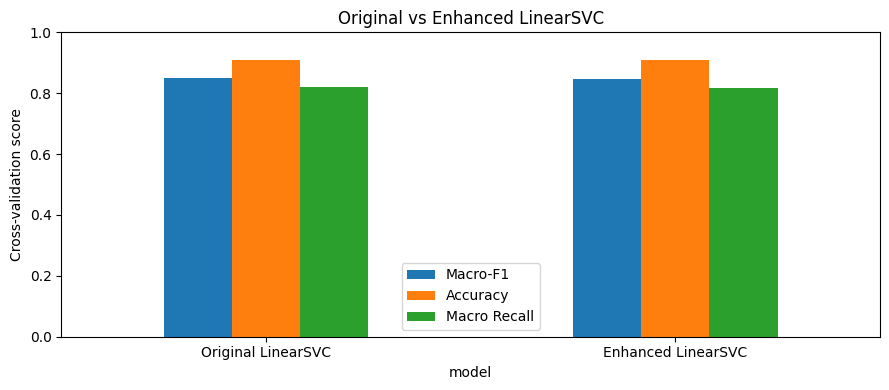

In [127]:
# original configuration
original_model = text_pipeline(
    LinearSVC(class_weight="balanced", random_state=SEED)
)

# enhanced feature extraction
enhanced_model = Pipeline([
    ("features", FeatureUnion([
        ("word", TfidfVectorizer(
            stop_words="english",
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ("char", TfidfVectorizer(
            analyzer="char_wb",
            ngram_range=(3, 5),
            min_df=2,
            sublinear_tf=True
        ))
    ])),
    ("model", LinearSVC(
        class_weight="balanced",
        random_state=SEED
    ))
])

# compare using the same cross-validation folds
scoring = {
    "macro_f1": "f1_macro",
    "accuracy": "accuracy",
    "ai_recall": "recall_macro"
}

original_cv = cross_validate(
    original_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

enhanced_cv = cross_validate(
    enhanced_model,
    X_train,
    y_train,
    cv=cv,
    scoring=scoring,
    n_jobs=1
)

# compare results
enhancement_results = pd.DataFrame({
    "model": ["Original LinearSVC", "Enhanced LinearSVC"],
    "cv_macro_f1": [
        original_cv["test_macro_f1"].mean(),
        enhanced_cv["test_macro_f1"].mean()
    ],
    "cv_accuracy": [
        original_cv["test_accuracy"].mean(),
        enhanced_cv["test_accuracy"].mean()
    ],
    "cv_macro_recall": [
        original_cv["test_ai_recall"].mean(),
        enhanced_cv["test_ai_recall"].mean()
    ]
})

print("Cross-validation comparison:")
print(enhancement_results.round(4).to_string(index=False))

improvement = (
    enhancement_results.loc[1, "cv_macro_f1"]
    - enhancement_results.loc[0, "cv_macro_f1"]
)

print("\nMacro-F1 difference:", round(improvement, 4))

# visualise comparison
ax = enhancement_results.set_index("model")[
    ["cv_macro_f1", "cv_accuracy", "cv_macro_recall"]
].plot(kind="bar", figsize=(9, 4), rot=0)

ax.set_title("Original vs Enhanced LinearSVC")
ax.set_ylabel("Cross-validation score")
ax.set_ylim(0, 1)
ax.legend(["Macro-F1", "Accuracy", "Macro Recall"])

plt.tight_layout()
plt.show()


### Combined TF-IDF Feature Evaluation

I combined word-level and character-level TF-IDF features to investigate whether additional text patterns could improve LinearSVC performance.

The original LinearSVC achieved a cross-validation macro-F1 of 0.8508, accuracy of 0.9098 and macro recall of 0.8219.

After combining the features, macro-F1 decreased to 0.8480, accuracy decreased to 0.9087 and macro recall decreased to 0.8174.

The additional character-level features therefore did not improve classification performance. I retained the original word-level TF-IDF configuration because it achieved better results across all three evaluation metrics.

### Classification Threshold Optimisation

I investigated classification threshold optimisation as another approach to improving predictive performance.

LinearSVC uses a decision score to determine which class an abstract belongs to. By default, the decision boundary is zero. Adjusting this threshold changes how readily the model assigns an abstract to the `ai` category.

I generated out-of-fold decision scores using five-fold stratified cross-validation on the training dataset. I then evaluated different thresholds using macro-F1 and AI recall.

The objective was to identify a threshold that improves performance across both classes without using the testing dataset during optimisation.

Class order: ['ai' 'classical']

Original OOF macro-F1: 0.8507
Optimised OOF macro-F1: 0.8514
Best threshold: -0.0042
AI recall: 0.6755
Improvement: 0.0007


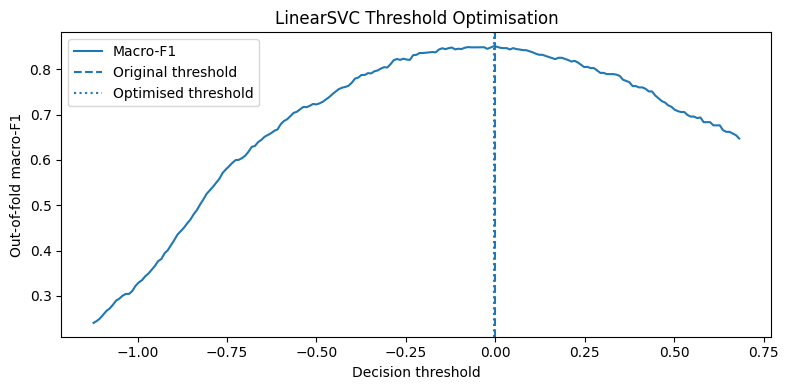

In [128]:
# optimise classification threshold
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, recall_score

# obtain out-of-fold decision scores
threshold_model = text_pipeline(
    LinearSVC(class_weight="balanced", random_state=SEED)
)

decision_scores = cross_val_predict(
    threshold_model,
    X_train,
    y_train,
    cv=cv,
    method="decision_function",
    n_jobs=1
)

# identify positive class
threshold_model.fit(X_train, y_train)
classes = threshold_model.named_steps["model"].classes_

print("Class order:", classes)

# convert scores so higher values indicate AI
ai_scores = (
    decision_scores
    if classes[1] == "ai"
    else -decision_scores
)

# evaluate candidate thresholds
thresholds = np.linspace(
    np.percentile(ai_scores, 5),
    np.percentile(ai_scores, 95),
    201
)

threshold_results = []

for threshold in thresholds:
    predictions = np.where(
        ai_scores >= threshold,
        "ai",
        "classical"
    )

    threshold_results.append({
        "threshold": threshold,
        "macro_f1": f1_score(
            y_train,
            predictions,
            average="macro"
        ),
        "ai_recall": recall_score(
            y_train,
            predictions,
            pos_label="ai"
        )
    })

threshold_results = pd.DataFrame(threshold_results)

best_row = threshold_results.loc[
    threshold_results["macro_f1"].idxmax()
]

best_threshold = float(best_row["threshold"])

# compare against original decision boundary
original_predictions = np.where(
    ai_scores >= 0,
    "ai",
    "classical"
)

original_f1 = f1_score(
    y_train,
    original_predictions,
    average="macro"
)

print("\nOriginal OOF macro-F1:", round(original_f1, 4))
print("Optimised OOF macro-F1:", round(best_row["macro_f1"], 4))
print("Best threshold:", round(best_threshold, 4))
print("AI recall:", round(best_row["ai_recall"], 4))
print("Improvement:", round(best_row["macro_f1"] - original_f1, 4))

# visualise threshold performance
fig, ax = plt.subplots(figsize=(8, 4))

ax.plot(
    threshold_results["threshold"],
    threshold_results["macro_f1"],
    label="Macro-F1"
)

ax.axvline(
    0,
    linestyle="--",
    label="Original threshold"
)

ax.axvline(
    best_threshold,
    linestyle=":",
    label="Optimised threshold"
)

ax.set_xlabel("Decision threshold")
ax.set_ylabel("Out-of-fold macro-F1")
ax.set_title("LinearSVC Threshold Optimisation")
ax.legend()

plt.tight_layout()
plt.show()


In [129]:
# validate threshold optimisation
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score

outer_cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEED
)

inner_cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=SEED
)

baseline_scores = []
optimised_scores = []
selected_thresholds = []

for train_idx, val_idx in outer_cv.split(X_train, y_train):
    X_inner = X_train.iloc[train_idx]
    y_inner = y_train.iloc[train_idx]

    X_outer = X_train.iloc[val_idx]
    y_outer = y_train.iloc[val_idx]

    model = text_pipeline(
        LinearSVC(
            class_weight="balanced",
            random_state=SEED
        )
    )

    # obtain inner cross-validation scores
    inner_scores = cross_val_predict(
        model,
        X_inner,
        y_inner,
        cv=inner_cv,
        method="decision_function",
        n_jobs=1
    )

    # orient scores towards the AI class
    model.fit(X_inner, y_inner)
    classes = model.named_steps["model"].classes_

    if classes[1] == "ai":
        ai_inner_scores = inner_scores
    else:
        ai_inner_scores = -inner_scores

    thresholds = np.linspace(
        np.percentile(ai_inner_scores, 5),
        np.percentile(ai_inner_scores, 95),
        201
    )

    # select threshold using inner folds
    scores = []

    for threshold in thresholds:
        predictions = np.where(
            ai_inner_scores >= threshold,
            "ai",
            "classical"
        )

        scores.append(
            f1_score(
                y_inner,
                predictions,
                average="macro"
            )
        )

    best_threshold = thresholds[np.argmax(scores)]
    selected_thresholds.append(best_threshold)

    # evaluate on unseen outer fold
    outer_scores = model.decision_function(X_outer)

    if classes[1] != "ai":
        outer_scores = -outer_scores

    baseline_predictions = np.where(
        outer_scores >= 0,
        "ai",
        "classical"
    )

    optimised_predictions = np.where(
        outer_scores >= best_threshold,
        "ai",
        "classical"
    )

    baseline_scores.append(
        f1_score(
            y_outer,
            baseline_predictions,
            average="macro"
        )
    )

    optimised_scores.append(
        f1_score(
            y_outer,
            optimised_predictions,
            average="macro"
        )
    )

# compare generalisation performance
validation_results = pd.DataFrame({
    "fold": range(1, 6),
    "original_macro_f1": baseline_scores,
    "optimised_macro_f1": optimised_scores,
    "selected_threshold": selected_thresholds
})

print(validation_results.round(4).to_string(index=False))

print("\nOriginal mean macro-F1:",
      round(np.mean(baseline_scores), 4))

print("Optimised mean macro-F1:",
      round(np.mean(optimised_scores), 4))

print("Mean improvement:",
      round(
          np.mean(optimised_scores)
          - np.mean(baseline_scores),
          4
      ))

 fold  original_macro_f1  optimised_macro_f1  selected_threshold
    1             0.8670              0.8636              0.0247
    2             0.8187              0.8227             -0.0859
    3             0.8297              0.8145              0.1144
    4             0.9174              0.9274             -0.1120
    5             0.8214              0.8060             -0.0850

Original mean macro-F1: 0.8508
Optimised mean macro-F1: 0.8468
Mean improvement: -0.004


### Threshold Optimisation Results

I evaluated different LinearSVC decision thresholds to determine whether adjusting the classification boundary could improve predictive performance.

The original decision threshold achieved an out-of-fold macro-F1 of 0.8507. After optimisation, the highest macro-F1 increased slightly to 0.8514 at a threshold of -0.0042, representing an improvement of 0.0007.

The optimised configuration achieved an AI recall of 0.6755. However, the selected threshold was very close to the original threshold of zero, and the improvement in macro-F1 was minimal.

The visualisation also shows that macro-F1 is highest around the original decision boundary and decreases as the threshold moves further away.

Since the threshold was selected using the same out-of-fold predictions used to report its performance, the small improvement may reflect optimisation on those predictions rather than better generalisation.

I therefore retained the original LinearSVC configuration until the threshold adjustment could be evaluated independently.

Feature selection comparison:
features  cv_macro_f1  cv_std
    1000       0.8619  0.0332
    3000       0.8621  0.0434
    5000       0.8619  0.0393
    8000       0.8533  0.0363
     all       0.8508  0.0375


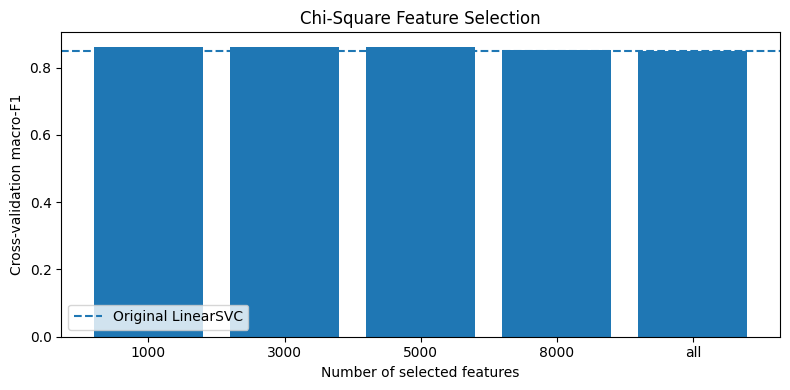

In [130]:
# evaluate feature selection

feature_scores = []

for k in [1000, 3000, 5000, 8000, "all"]:
    selected_model = Pipeline([
        ("tfidf", TfidfVectorizer(
            stop_words="english",
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True
        )),
        ("selection", SelectKBest(
            score_func=chi2,
            k=k
        )),
        ("model", LinearSVC(
            class_weight="balanced",
            random_state=SEED
        ))
    ])

    scores = cross_val_score(
        selected_model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=1
    )

    feature_scores.append({
        "features": str(k),
        "cv_macro_f1": scores.mean(),
        "cv_std": scores.std()
    })

feature_results = pd.DataFrame(feature_scores)

print("Feature selection comparison:")
print(feature_results.round(4).to_string(index=False))

# visualise results
fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    feature_results["features"],
    feature_results["cv_macro_f1"]
)

ax.axhline(
    original_scores.mean(),
    linestyle="--",
    label="Original LinearSVC"
)

ax.set_xlabel("Number of selected features")
ax.set_ylabel("Cross-validation macro-F1")
ax.set_title("Chi-Square Feature Selection")
ax.legend()

plt.tight_layout()
plt.show()

### Feature Selection Results

I evaluated chi-square feature selection to determine whether retaining fewer TF-IDF features could improve classification performance.

The original LinearSVC configuration, which retained all features, achieved a cross-validation macro-F1 of 0.8508.

Selecting 1,000 features increased macro-F1 to 0.8619, while selecting 3,000 features achieved the highest score of 0.8621. Selecting 5,000 features also produced a macro-F1 of 0.8619.

Performance decreased to 0.8533 when 8,000 features were retained, although this remained slightly higher than the original configuration.

The results suggest that some TF-IDF features may introduce noise rather than contribute useful information to classification. Reducing the feature space improved average cross-validation performance in this experiment.

I selected the 3,000-feature configuration for further evaluation because it achieved the highest mean macro-F1, representing an improvement of 0.0113 over the original LinearSVC.

However, the standard deviation of 0.0434 indicates that performance varied across the cross-validation folds. 

Held-out test comparison:
                     model  test_accuracy  test_macro_f1  ai_recall
        Original LinearSVC           0.92         0.8729     0.7447
Feature-selected LinearSVC           0.92         0.8729     0.7447

Feature-selected classification report:
              precision    recall  f1-score   support

          ai       0.85      0.74      0.80        47
   classical       0.93      0.97      0.95       178

    accuracy                           0.92       225
   macro avg       0.89      0.86      0.87       225
weighted avg       0.92      0.92      0.92       225



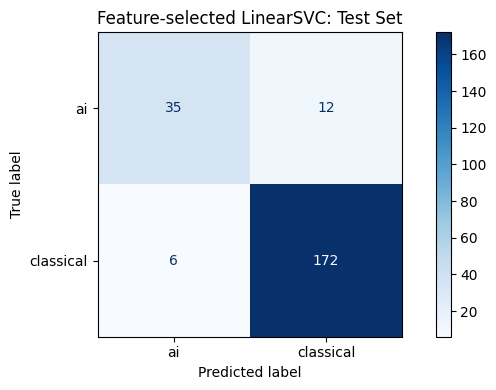


Test macro-F1 difference: 0.0


In [131]:
# evaluate selected feature configuration
best_feature_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("selection", SelectKBest(
        score_func=chi2,
        k=3000
    )),
    ("model", LinearSVC(
        class_weight="balanced",
        random_state=SEED
    ))
])

best_feature_model.fit(X_train, y_train)

# evaluate original model
original_model = text_pipeline(
    LinearSVC(class_weight="balanced", random_state=SEED)
)

original_model.fit(X_train, y_train)

original_predictions = original_model.predict(X_test)
enhanced_predictions = best_feature_model.predict(X_test)

# compare held-out performance
final_comparison = pd.DataFrame({
    "model": ["Original LinearSVC", "Feature-selected LinearSVC"],
    "test_accuracy": [
        accuracy_score(y_test, original_predictions),
        accuracy_score(y_test, enhanced_predictions)
    ],
    "test_macro_f1": [
        f1_score(y_test, original_predictions, average="macro"),
        f1_score(y_test, enhanced_predictions, average="macro")
    ],
    "ai_recall": [
        recall_score(y_test, original_predictions, pos_label="ai"),
        recall_score(y_test, enhanced_predictions, pos_label="ai")
    ]
})

print("Held-out test comparison:")
print(final_comparison.round(4).to_string(index=False))

print("\nFeature-selected classification report:")
print(classification_report(
    y_test,
    enhanced_predictions,
    zero_division=0
))

# visualise enhanced model errors
fig, ax = plt.subplots(figsize=(7, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    enhanced_predictions,
    ax=ax,
    cmap="Blues"
)

ax.set_title("Feature-selected LinearSVC: Test Set")
plt.tight_layout()
plt.show()

# report improvement
improvement = (
    final_comparison.loc[1, "test_macro_f1"]
    - final_comparison.loc[0, "test_macro_f1"]
)

print("\nTest macro-F1 difference:", round(improvement, 4))


### Final Feature Selection Evaluation

I selected the 3,000-feature configuration because it achieved the highest cross-validation macro-F1 of 0.8621, compared with 0.8508 for the original LinearSVC. This represents an improvement of 0.0113.

I then evaluated both configurations using the same held-out testing dataset to determine whether the improvement extended to unseen abstracts.

Both models achieved 92.0% test accuracy, a macro-F1 of 0.8729 and an AI recall of 0.7447. Therefore, although feature selection improved average cross-validation performance, it did not improve performance on the held-out testing dataset.

The results suggest that reducing the feature space may help the model during cross-validation, but the improvement was not reflected in the final test predictions.

I retained the original LinearSVC for deployment because it achieved the same testing performance without requiring an additional feature selection stage.

### Predictive Performance Enhancement Conclusion

I investigated four approaches to improving LinearSVC classification performance: hyperparameter tuning, combined word-level and character-level TF-IDF features, threshold optimisation and chi-square feature selection.

Hyperparameter tuning produced no improvement, with both the original and tuned configurations achieving a cross-validation macro-F1 of 0.8508.

Combining word-level and character-level features reduced macro-F1 from 0.8508 to 0.8480. Threshold optimisation also failed to improve generalisation, with nested cross-validation macro-F1 decreasing from 0.8508 to 0.8468.

Chi-square feature selection produced the strongest enhancement result. Selecting 3,000 features increased cross-validation macro-F1 from 0.8508 to 0.8621.

However, both the original and feature-selected LinearSVC achieved the same held-out test macro-F1 of 0.8729.

Therefore, feature selection demonstrated an improvement in average cross-validation performance, but no additional improvement in held-out test performance. I retained the original LinearSVC as the final deployment model.

### Web Interface Deployment

Deployment link: https://naturallanguageprocessing-hzgke6vvsslq2nv3ux5fid.streamlit.app/

I selected LinearSVC as the final classification model because it achieved the highest cross-validation macro-F1 of 0.8508.

The model achieved 92.0% accuracy and a macro-F1 of 0.873 on the testing dataset. However, its recall of 0.74 for the `ai` category indicates that some AI abstracts may still be incorrectly classified as classical.

I saved the trained pipeline using Joblib. The pipeline contains both the TF-IDF vectoriser and LinearSVC classifier, allowing new abstracts to be classified without retraining.

I developed a Streamlit application that allows users to enter a research abstract and obtain a predicted classification of either `ai` or `classical`.

The application loads the saved model from the deployment folder and displays the predicted category. It also checks whether the user has entered an abstract before attempting classification.